# Which sensor gives more reliable VRU trajectories: NewSense or Ouster?

**Purpose.** At intersection K305 the team studies pedestrians and cyclists (VRUs). So far we have used the
NewSense object list. It gives one physical object several track IDs and has flickering detections. An Ouster
LiDAR object list exists for part of the morning of 29.10. This notebook compares the two sensors on the same
time and place and builds a scorecard from the numbers. The recommendation at the end is generated from those
numbers, so it reflects whichever run produced it.

**Data used.**
- NewSense object lists, 5-minute JSON files at 10 Hz, 29.10 07:20–11:25 CET, the same clock hours on 28.10, and
  02:00–02:30 CET on 29.10 for the night check.
- Ouster object lists, gzipped JSON lines at 10 Hz, 29.10 07:20–11:25 CET. The file `..._06-20-00` is skipped
  because it starts with stale frames.

**Key facts a reader needs.**
- **Time.** Ouster file names give the *end* of their window in UTC. Data is always selected by timestamp, never
  by file name. The Ouster clock runs about 0.08 s ahead of NewSense.
- **Recalibration.** The Ouster was recalibrated at about 08:13 CET.
  - **Epoch A** is 07:20–08:13 CET (secondary).
  - **Epoch B** is 08:15–11:25 CET (primary).
  - 08:13–08:15 CET is dropped from both sensors.
- **Coordinates.** All positions are shown in the epoch-B Ouster frame, called the *common frame*:
  - NewSense is moved into it with a fitted 2D rigid transform.
  - Epoch-A Ouster data uses that transform composed with the inverse of the epoch-A transform.
- **Variants.**
  - *filtered* (primary): NewSense detections with score ≥ 0.25, and Ouster tracks with a known class.
  - *raw*: all detections.
- **No ground truth.** Neither sensor is ground truth. An unmatched detection is either a false detection by one
  sensor or a miss by the other.

**Run mode.** `sample` mode (the default) uses 10 minutes per epoch. That is enough to test the code but not
to choose a sensor, so all sample results are **provisional**. Set `SENSOR_COMPARE_MODE=full` to run on all data.

## 1. Setup and run mode

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import sensor_compare as sc

RUN_MODE = os.environ.get("SENSOR_COMPARE_MODE", "sample")   # "sample" or "full"
cfg = sc.mode_config(RUN_MODE)
TAG = "(PROVISIONAL, sample)" if RUN_MODE == "sample" else "(full run)"
sc.plot_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
T_START = time.time()
print("run mode:", RUN_MODE, "| epochs:", {k: [str(sc.to_cet(v)) for v in r] for k, r in cfg["epochs"].items()})
if RUN_MODE == "sample":
    display(Markdown("**PROVISIONAL: sample mode, 10 minutes per epoch. Numbers below test the code; they do not decide between the sensors.**"))

run mode: sample | epochs: {'A': ['2026-10-29 08:00:00', '2026-10-29 08:10:00'], 'B': ['2026-10-29 09:15:00', '2026-10-29 09:25:00']}


**PROVISIONAL: sample mode, 10 minutes per epoch. Numbers below test the code; they do not decide between the sensors.**

Full mode loads 49 NewSense files for 29.10, 47 Ouster files, 6 night files and 49 NewSense files for 28.10.
This check only lists those files and confirms they exist. It does not open them.

In [2]:
display(sc.check_full_mode_files())
FILES = sc.files_for_mode(RUN_MODE)
print({k: len(v) for k, v in FILES.items()})

,set,n_files,expected,all_exist,first,last
0,ouster,47,47,True,object_list+occupations.log.2026-10-29_06-25-0...,object_list+occupations.log.2026-10-29_10-25-0...
1,newsense_29,49,49,True,k305_object_list_2026-10-29_07-20_to_07-24.json,k305_object_list_2026-10-29_11-20_to_11-24.json
2,newsense_night,6,6,True,k305_object_list_2026-10-29_02-00_to_02-04.json,k305_object_list_2026-10-29_02-25_to_02-29.json
3,newsense_28,49,49,True,k305_object_list_2026-10-28_07-20_to_07-24.json,k305_object_list_2026-10-28_11-20_to_11-24.json


{'ouster': 4, 'newsense_29': 4, 'newsense_night': 1, 'newsense_28': 2}


## 2. Loading, alignment validation and the common region

Each source file is flattened once into Parquet in native coordinates (`output/cache/`). Transforms are applied
in memory after loading. Missing caches are built here, with one progress line per file.

In [3]:
t0 = time.time()
all_files = sorted({p for v in FILES.values() for p in v})
build_info = sc.build_cache(all_files, max_workers=6)
T_CACHE = time.time() - t0
print(f"cache build: {T_CACHE:.0f} s, cache size {sc.cache_size_mb():.0f} MB")

cache: 0 of 11 files already cached, 11 to parse


cache: 0 of 11 files already cached, 11 to parse


  [1/11] k305_object_list_2026-10-28_09-20_to_09-24.det.parquet: 3001 frames, 55590 detections, 0 duplicate ts, 0.9 s (elapsed 2 s)


  [2/11] k305_object_list_2026-10-28_09-15_to_09-19.det.parquet: 3000 frames, 47505 detections, 0 duplicate ts, 0.7 s (elapsed 2 s)


  [1/11] k305_object_list_2026-10-28_09-20_to_09-24.det.parquet: 3001 frames, 55590 detections, 0 duplicate ts, 0.9 s (elapsed 2 s)
  [2/11] k305_object_list_2026-10-28_09-15_to_09-19.det.parquet: 3000 frames, 47505 detections, 0 duplicate ts, 0.7 s (elapsed 2 s)


  [3/11] k305_object_list_2026-10-29_02-00_to_02-04.det.parquet: 3000 frames, 24584 detections, 0 duplicate ts, 0.4 s (elapsed 2 s)


... (9 outputs left out)

  [10/11] object_list+occupations.log.2026-10-29_07-05-00.det.parquet: 2951 frames, 83749 detections, 21 duplicate ts, 2.2 s (elapsed 3 s)


  [11/11] k305_object_list_2026-10-29_09-20_to_09-24.det.parquet: 3000 frames, 52402 detections, 0 duplicate ts, 0.7 s (elapsed 3 s)


  [8/11] object_list+occupations.log.2026-10-29_08-25-00.det.parquet: 3000 frames, 74867 detections, 0 duplicate ts, 2.2 s (elapsed 3 s)
  [9/11] k305_object_list_2026-10-29_09-15_to_09-19.det.parquet: 3000 frames, 51096 detections, 0 duplicate ts, 0.8 s (elapsed 3 s)
  [10/11] object_list+occupations.log.2026-10-29_07-05-00.det.parquet: 2951 frames, 83749 detections, 21 duplicate ts, 2.2 s (elapsed 3 s)
  [11/11] k305_object_list_2026-10-29_09-20_to_09-24.det.parquet: 3000 frames, 52402 detections, 0 duplicate ts, 0.7 s (elapsed 3 s)


cache build: 3 s, cache size 18 MB


In [4]:
t0 = time.time()
RAW = {"newsense": sc.load_sensor("newsense", FILES["newsense_29"], cfg["epochs"], day="29"),
       "ouster": sc.load_sensor("ouster", FILES["ouster"], cfg["epochs"], day="29")}
VAR = {(s, v): sc.make_variant(RAW[s], v) for s in sc.SENSORS for v in ["filtered", "raw"]}
for (s, v), sd in VAR.items():
    print(f"{s:9s} {v:8s} detections {len(sd.det):>9,d}  tracks {sd.det.trk.nunique():>7,d}  frames {len(sd.frames):>7,d}")
print("track IDs reused after >", sc.TRACK_SPLIT_GAP, "s silence (split into separate tracks):",
      {s: RAW[s].n_id_reuse_splits for s in sc.SENSORS})
print(f"load: {time.time() - t0:.0f} s, peak RSS {sc.rss_mb():.0f} MB")

newsense  filtered detections   138,691  tracks   1,148  frames  12,000
newsense  raw      detections   212,954  tracks   1,599  frames  12,000
ouster    filtered detections   271,300  tracks   2,057  frames  11,935
ouster    raw      detections   281,239  tracks   3,098  frames  11,935
track IDs reused after > 30.0 s silence (split into separate tracks): {'newsense': 0, 'ouster': 0}
load: 1 s, peak RSS 582 MB


### Validation gates
The gates run before any metric and stop the notebook if they fail.

**Gate 1: alignment.** For each 5-minute window this is the share of NewSense vehicles faster than 4 m/s that
have an Ouster vehicle within 1 m in the time-paired frame. Only paired frames count. Values around 0.8–0.9 mean
the transforms and clocks line up.
- The gate fails if the median over windows is below 0.70, or if any epoch-B window is below 0.50.
- The figure also documents the recalibration: each epoch is aligned with its own transform.

,epoch,window,share,n,window_cet
0,A,1793257200,0.873,10035,2026-10-29 08:00:00
1,A,1793257500,0.848,8209,2026-10-29 08:05:00
2,B,1793261700,0.875,8571,2026-10-29 09:15:00
3,B,1793262000,0.861,10462,2026-10-29 09:20:00


{'gate': 'alignment', 'median_share': 0.867, 'min_epochB_window': 0.861, 'passed': True}


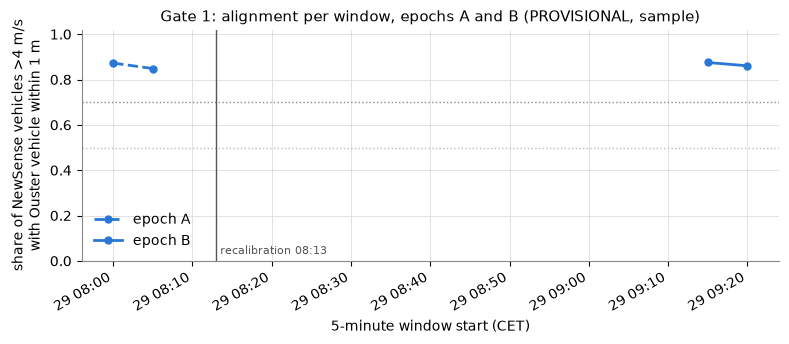

In [5]:
ALIGN = sc.alignment_share(VAR[("newsense", "filtered")], RAW["ouster"])
sc.save_table(ALIGN, cfg, "gate1_alignment_per_window")
display(ALIGN)
GATE1 = sc.gate_alignment(ALIGN)
print(GATE1)
fig = sc.plot_alignment(ALIGN, TAG); sc.save_fig(fig, cfg, "gate1_alignment"); plt.show()

**Gate 2: clock offset.** The same share is computed for clock offsets from −0.30 to +0.30 s, on up to three
epoch-B windows spread over the epoch. The best offset must lie between 0 and +0.15 s. After that, +0.08 s is
used everywhere.

At 10 Hz neighbouring offsets often select the same frame, so the curve has steps.

window_cet,2026-10-29 09:15:00,2026-10-29 09:20:00
offset,,
-0.30,0.002,0.003
-0.25,0.008,0.006
-0.20,0.008,0.006
-0.15,0.078,0.092
-0.10,0.078,0.092
-0.05,0.461,0.496
0.00,0.461,0.496
0.05,0.875,0.861
0.10,0.875,0.861


{'gate': 'clock_offset', 'best_offset_s': 0.05, 'share_at_best': 0.868, 'passed': True}


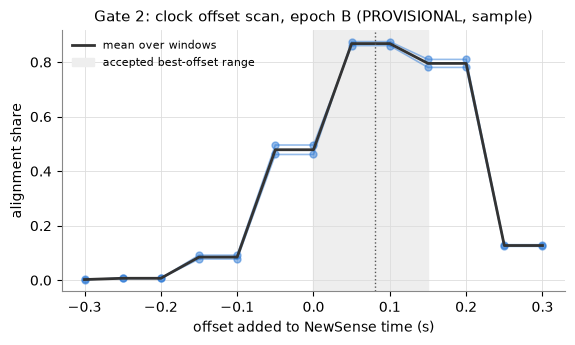

In [6]:
b_windows = np.sort(np.unique(sc._window_of(VAR[("newsense", "filtered")].det.query("epoch == 'B'").ts)))
scan_windows = np.unique(b_windows[np.round(np.linspace(0, len(b_windows) - 1, 3)).astype(int)])
SCAN = sc.clock_offset_scan(VAR[("newsense", "filtered")], RAW["ouster"], scan_windows)
sc.save_table(SCAN, cfg, "gate2_clock_offset_scan")
display(SCAN.pivot_table(index="offset", columns="window_cet", values="share"))
GATE2 = sc.gate_clock(SCAN)
print(GATE2)
fig = sc.plot_clock(SCAN, TAG); sc.save_fig(fig, cfg, "gate2_clock_offset"); plt.show()

**Gate 3: coverage.** After filtering, each sensor must have detections in every 5-minute window of both
epochs. A shorter last window, such as epoch A ending at 08:13 in full mode, still has to contain data.

In [7]:
COVER = sc.gate_coverage({s: VAR[(s, "filtered")] for s in sc.SENSORS}, cfg["epochs"])
sc.save_table(COVER, cfg, "gate3_coverage")
display(COVER)
print("Gate 3 (coverage): passed")

,epoch,window,duration,n_det_newsense,n_det_ouster,window_cet
0,A,1793257200,300,40731,80100,2026-10-29 08:00:00
1,A,1793257500,300,32067,60427,2026-10-29 08:05:00
2,B,1793261700,300,32671,58357,2026-10-29 09:15:00
3,B,1793262000,300,33222,72416,2026-10-29 09:20:00


Gate 3 (coverage): passed


### Common region
The Ouster sees about ±80 m and NewSense about ±40 m, so every comparison is restricted to the area both see.
- **Region cells.** A 2 m cell belongs to the region if each sensor has enough moving detections there (speed
  ≥ 1 m/s) in epoch B. The threshold is set by the run mode.
- **Which data is used.** Detection-level metrics use detections inside the region. Track-level metrics use
  tracks with at least half of their detections inside it.
- **Reuse.** The same region is used for epoch A, the night check and 28.10.

,region_cells,sensor,variant,epoch,det_share_in_region,tracks_in_region
0,450,newsense,filtered,A,0.584,428
1,450,newsense,filtered,B,0.656,487
2,450,newsense,raw,A,0.425,474
3,450,newsense,raw,B,0.450,552
4,450,ouster,filtered,A,0.387,230
5,450,ouster,filtered,B,0.392,286
6,450,ouster,raw,A,0.384,365
7,450,ouster,raw,B,0.391,396


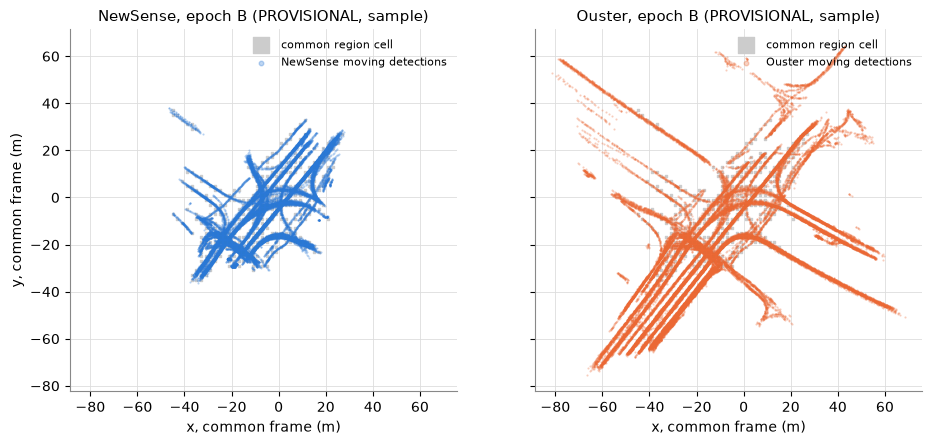

In [8]:
REGION = sc.build_region(VAR[("newsense", "filtered")], VAR[("ouster", "filtered")], "B", cfg["region_min"])
VAR = {k: sc.add_region(sd, REGION) for k, sd in VAR.items()}
REG_TAB = pd.DataFrame([dict(sensor=s, variant=v, epoch=ep,
                             det_share_in_region=float(sd.det.loc[sd.det.epoch == ep, "in_region"].mean()),
                             tracks_in_region=int(sd.det.loc[(sd.det.epoch == ep) & sd.det.trk_in_region, "trk"].nunique()))
                        for (s, v), sd in VAR.items() for ep in sorted(cfg["epochs"])])
REG_TAB.insert(0, "region_cells", len(REGION.keys))
sc.save_table(REG_TAB, cfg, "common_region")
display(REG_TAB)
fig = sc.plot_region(REGION, VAR[("newsense", "filtered")], VAR[("ouster", "filtered")], "B", TAG)
sc.save_fig(fig, cfg, "common_region_map"); plt.show()

## 3. Stream health
Stream health is measured on the stream of emitted frames, before any track logic, and does not depend on the
variant.
- **Measures.** Frames per 5 minutes (3000 expected at 10 Hz, scaled for shorter windows), the share of frame
  gaps above 0.15 s, duplicate timestamps (the second frame is dropped), and the longest gap.
- **Reading the figure.** A ratio of 1.0 is a complete stream. Dips mean dropped frames, which also lower the
  number of frames that can be paired across sensors.

,sensor,day,epoch,n_frames,frames_per_5min,min_window_frame_ratio,gap_share_gt_0p15s,gaps_ge_0p2s,duplicate_ts,longest_gap_s
0,newsense,29,A,6000,3000.0,1.000,0.000e+00,0,0,0.102
1,newsense,29,B,6000,3000.0,1.000,0.000e+00,0,0,0.103
2,ouster,29,A,5939,2969.5,0.984,9.936e-03,23,32,0.201
3,ouster,29,B,5996,2998.0,0.999,3.336e-04,0,2,0.200


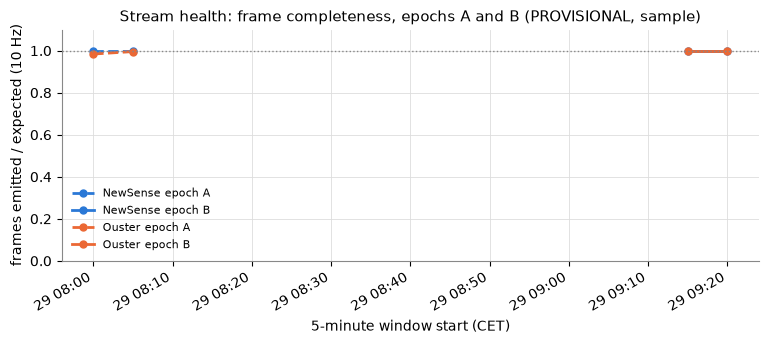

In [9]:
HEALTH = pd.concat([sc.stream_health(RAW[s]) for s in sc.SENSORS], ignore_index=True)
HEALTH_W = pd.concat([sc.stream_health_windows(RAW[s]) for s in sc.SENSORS], ignore_index=True)
sc.save_table(HEALTH, cfg, "stream_health"); sc.save_table(HEALTH_W, cfg, "stream_health_per_window")
display(HEALTH)
fig = sc.plot_stream(HEALTH_W, TAG); sc.save_fig(fig, cfg, "stream_health"); plt.show()

## 4. Single-sensor track quality
Each sensor is judged on its own: per group, per epoch and per variant, on tracks in the common region. Lower
is better for every panel.

| Metric | What it measures |
| :--- | :--- |
| Flickering | Share of tracks shorter than 1 s |
| Gaps inside tracks | Missing frames between a track's first and last detection, counted in the sensor's own emitted frames |
| Class stability | Tracks that switch between known classes |
| Implausible motion | Frame steps faster than 4 / 15 / 30 m/s for ped / bike / veh |
| Jitter | RMS of the second difference of position, on tracks that move at least 3 m |
| ID handovers | A track ends and, within 2 s, a new track of the same group starts within 1.5 m of the extrapolated position |

- **Handovers** count ID switches that each sensor causes by itself.
- **Shares near zero are good.** A handover rate of tens per 100 tracks means a VRU trajectory is regularly
  split into several IDs.
- **Built-in advantage.** NewSense reports one class and one score per track and does not report gaps inside a
  track: it starts a new ID instead. So the gap and class-stability rows can favour NewSense by design rather
  than by quality. The conclusion therefore checks the decision both with and without those rows.

single-sensor metrics: 3 s


epoch                           B                                                               A                                                      
group                         ped                 bike                   veh                  ped                 bike                   veh           
sensor                   newsense     ouster  newsense     ouster   newsense     ouster  newsense     ouster  newsense     ouster   newsense     ouster
n_tracks                6.500e+01     95.000    18.000  1.200e+01    404.000  1.790e+02    60.000     38.000    29.000  2.300e+01    339.000  1.690e+02
n_det                   5.335e+03  10578.000  2063.000  3.555e+03  35334.000  3.407e+04  5982.000  14007.000  2666.000  5.038e+03  33855.000  3.564e+04
flicker_track_share     4.615e-02      0.295     0.056  8.333e-02      0.045  9.497e-02     0.150      0.158     0.172  4.348e-02      0.021  3.550e-02
flicker_det_share       5.623e-03      0.013     0.005  3.094e-03      0.005  1.849e-03     0.015      0.002     0.019  5.955e-04      0.002  6.173e-04
gap_track_share         0.000e+00      0.105     0.000  2.500e-01      0.000  1.006e-01     0.000      0.184     0.000  2.609e-01      0.000  1.065e-01
gap_mean_missing_share  0.000e+00      0.015     0.000  1.938e-02      0.000  1.190e-02     0.000      0.015     0.000  3.737e-02      0.000  1.213e-02
class_multi_share       0.000e+00      0.000     0.000  1.667e-01      0.000  0.000e+00     0.000      0.079     0.000  3.043e-01      0.000  0.000e+00
unk_det_share           0.000e+00      0.042     0.000  8.805e-02      0.000  6.681e-02     0.000      0.042     0.000  7.027e-02      0.000  1.066e-02
implausible_step_share  7.590e-04      0.018     0.000  2.825e-04      0.000  2.657e-04     0.010      0.011     0.000  1.598e-03      0.000  1.975e-04
step_speed_p99          3.100e+00      5.443     5.873  1.034e+01     12.296  1.467e+01     3.925      4.164     6.337  1.179e+01     12.626  1.479e+01
n_steps                 5.270e+03  10468.000  2045.000  3.540e+03  34930.000  3.387e+04  5922.000  13961.000  2637.000  5.007e+03  33516.000  3.545e+04
jitter_rms_m            6.858e-02      0.173     0.087  1.107e-01      0.160  2.248e-01     0.065      0.106     0.089  1.404e-01      0.151  2.010e-01
n_jitter                3.637e+03   9989.000  1809.000  3.124e+03  31154.000  3.346e+04  4142.000  13281.000  1858.000  4.813e+03  31246.000  3.513e+04
static_long_count       1.000e+00      0.000     1.000  2.000e+00      6.000  0.000e+00     3.000      2.000     2.000  0.000e+00      4.000  0.000e+00
static_long_det_share   5.211e-02      0.000     0.050  9.367e-02      0.038  0.000e+00     0.128      0.025     0.181  0.000e+00      0.022  0.000e+00
handovers_per_100       1.406e+01     49.451     0.000  1.818e+01      1.750  3.371e+00    22.034     21.622     3.448  1.739e+01      1.212  2.454e+00
n_handover_tracks       6.400e+01     91.000    17.000  1.100e+01    400.000  1.780e+02    59.000     37.000    29.000  2.300e+01    330.000  1.630e+02

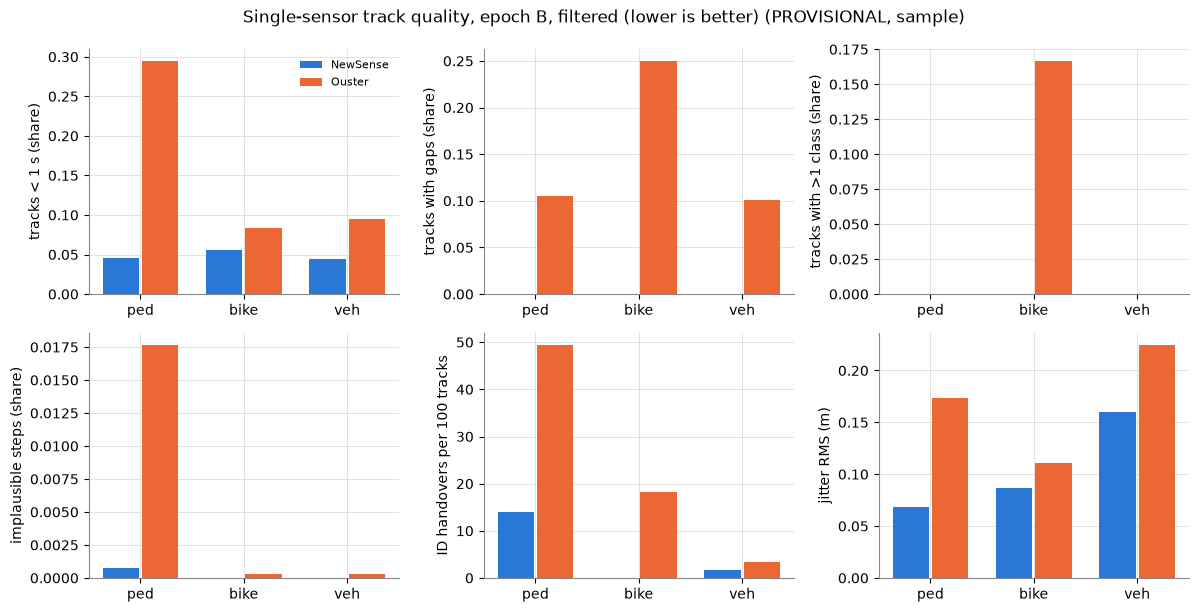

In [10]:
t0 = time.time()
single_rows, TRACKS = [], {}
for (s, v), sd in VAR.items():
    m, tt = sc.single_sensor_metrics(sd, v)
    single_rows.append(m); TRACKS[(s, v)] = tt
SINGLE = pd.concat(single_rows, ignore_index=True)
order = {g: i for i, g in enumerate(sc.GROUPS)}
SINGLE = SINGLE.sort_values(["variant", "epoch", "group", "sensor"], key=lambda c: c.map(order) if c.name == "group" else c,
                            ascending=[True, False, True, True]).reset_index(drop=True)
sc.save_table(SINGLE, cfg, "single_sensor_metrics")
print(f"single-sensor metrics: {time.time() - t0:.0f} s")
display(SINGLE[SINGLE.variant == "filtered"].set_index(["epoch", "group", "sensor"]).drop(columns=["day", "variant"]).T)
fig = sc.plot_single(SINGLE, "B", "filtered", TAG); sc.save_fig(fig, cfg, "single_sensor_epochB"); plt.show()

## 5. Cross-sensor comparison: same time, same place
This is the core of the comparison. It uses the filtered variants, with epoch B as the primary result and epoch A
as the secondary one.
- **Frame pairing.** Each NewSense frame is paired with the Ouster frame nearest to `ts + 0.08 s`, if that frame
  is within 0.06 s.
- **Matching.** In each paired frame, detections are matched one-to-one on centre distance (Hungarian
  assignment, class ignored, at most 2 m). The matched pairs are cached.

In [11]:
t0 = time.time()
NSF, OUF = VAR[("newsense", "filtered")], VAR[("ouster", "filtered")]
MATCHES, PSTATS, PAIR = sc.match_detections(NSF, OUF, RUN_MODE, "filtered")
sc.mark_matched(NSF, OUF, MATCHES, PAIR)
PAIR_TAB = pd.DataFrame([PSTATS]).assign(ns_unpaired_share=lambda d: d.ns_unpaired / d.ns_frames,
                                         median_match_dist_m=float(MATCHES["dist"].median()))
sc.save_table(PAIR_TAB, cfg, "frame_pairing")
display(PAIR_TAB)
print(f"matching: {time.time() - t0:.0f} s, peak RSS {sc.rss_mb():.0f} MB")

,ns_frames,ns_unpaired,ns_unpaired_by_conflict,ou_frames,ou_unpaired,n_pairs,ns_unpaired_share,median_match_dist_m
0,12000,77,71,11935,12,86007,0.006,0.303


matching: 1 s, peak RSS 645 MB


### 5.1 Confirmation rate
This is the share of a sensor's detections, in paired frames and inside the region, that the other sensor also
reports within 2 m. It is split into moving tracks (net displacement ≥ 3 m) and static tracks.
- **Reading the figure.** Higher is better.
- **Caution.** An unmatched detection is either a false detection by this sensor or a miss by the other. The data
  alone cannot tell which.
- **Static tracks.** Low static rates may be ghosts on fixed structures, or people waiting whom the other sensor
  misses.

sensor              newsense  ouster
epoch group motion                  
B     bike  all        0.952   0.741
            moving     0.985   0.783
            static     0.687   0.413
      ped   all        0.895   0.515
            moving     0.958   0.522
            static     0.754   0.365
      veh   all        0.906   0.829
            moving     0.958   0.830
            static     0.436   0.771
A     bike  all        0.938   0.653
            moving     0.978   0.641
            static     0.836   0.958
      ped   all        0.950   0.537
            moving     0.958   0.554
            static     0.930   0.225
      veh   all        0.934   0.809
            moving     0.937   0.809
            static     0.892   0.859

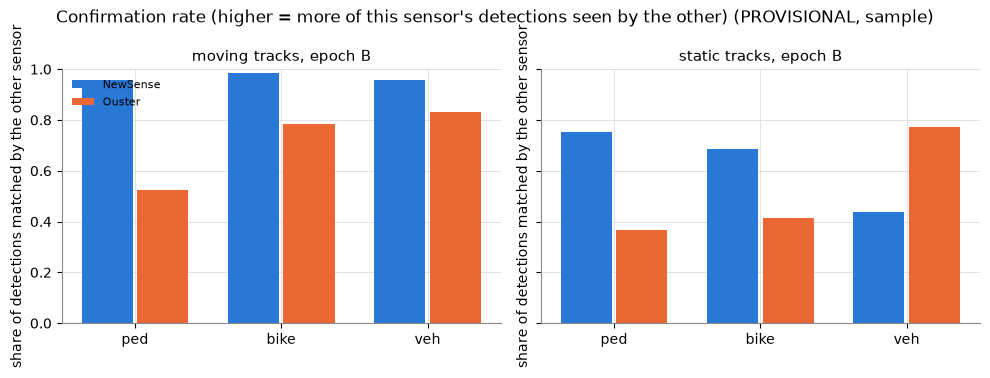

In [12]:
CONF = pd.concat([sc.confirmation_rates(NSF, TRACKS[("newsense", "filtered")]),
                  sc.confirmation_rates(OUF, TRACKS[("ouster", "filtered")])], ignore_index=True)
sc.save_table(CONF, cfg, "confirmation_rates")
display(CONF.pivot_table(index=["epoch", "group", "motion"], columns="sensor", values="confirmation_rate")
        .sort_index(level=[0, 1], ascending=[False, True]))
fig = sc.plot_confirmation(CONF, "B", TAG); sc.save_fig(fig, cfg, "confirmation_epochB"); plt.show()

### 5.2 Class agreement
The confusion matrix of track groups over matched pairs in epoch B. Rows are NewSense groups, columns are Ouster
groups. Mass off the diagonal means the sensors disagree on what the object is.

In [13]:
CONFUSION = {ep: sc.class_confusion(MATCHES, ep) for ep in sorted(cfg["epochs"])}
for ep, cm in CONFUSION.items():
    sc.save_table(cm, cfg, f"class_confusion_epoch{ep}", index=True)
display(CONFUSION["B"])

Ouster group,ped,bike,veh,unk
NewSense group,,,,
ped,4754,260,0,0
bike,280,1911,0,0
veh,412,996,33133,0
unk,0,0,0,0


### 5.3 ID fragmentation seen by the other sensor
This measures the "several IDs for one object" complaint directly.
- **Method.** For every track of one sensor with at least 30 matched detections, count the distinct IDs of the
  *other* sensor that cover at least 5 of those matched frames.
- **Attribution.** Ouster tracks that map to several NewSense IDs measure **NewSense** fragmentation. NewSense
  tracks that map to several Ouster IDs measure **Ouster** fragmentation. The figure is labelled by the sensor
  whose fragmentation is measured.
- **Reading the figure.** Lower is better. Values near 0 mean one ID per object.

,direction,measures_fragmentation_of,epoch,group,n_tracks,mean_n_ids,share_n_ids_ge2,changes,minutes,id_changes_per_min
0,ou->ns,newsense,A,bike,18,1.667,0.500,13,5.110,2.544
1,ou->ns,newsense,A,ped,23,3.217,0.739,132,14.478,9.117
2,ou->ns,newsense,A,veh,150,1.133,0.093,29,39.227,0.739
3,ou->ns,newsense,B,bike,8,1.875,0.375,40,3.882,10.305
4,ou->ns,newsense,B,ped,31,1.968,0.484,50,7.582,6.595
5,ou->ns,newsense,B,veh,153,1.144,0.111,27,37.347,0.723
6,ns->ou,ouster,A,bike,13,1.308,0.308,81,3.950,20.506
7,ns->ou,ouster,A,ped,31,1.065,0.032,10,8.618,1.160
8,ns->ou,ouster,A,veh,275,1.040,0.029,38,49.662,0.765
9,ns->ou,ouster,B,bike,12,1.167,0.167,8,3.123,2.561


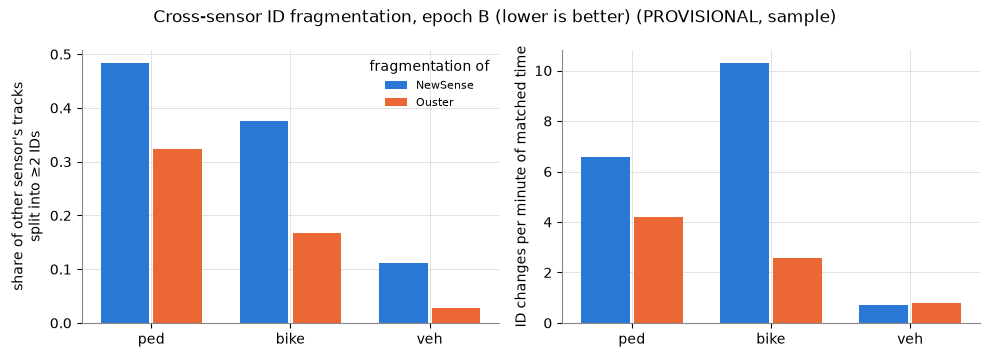

In [14]:
fr1, per1 = sc.fragmentation(MATCHES, "ou->ns", TRACKS[("ouster", "filtered")])
fr2, per2 = sc.fragmentation(MATCHES, "ns->ou", TRACKS[("newsense", "filtered")])
FRAG = pd.concat([fr1, fr2], ignore_index=True)
sc.save_table(FRAG, cfg, "fragmentation")
display(FRAG)
fig = sc.plot_fragmentation(FRAG, "B", TAG); sc.save_fig(fig, cfg, "fragmentation_epochB"); plt.show()

### 5.4 Unconfirmed tracks and video-check candidates
An unconfirmed track has under 10% of its paired-frame detections matched by the other sensor.
- **Map.** Clusters at fixed places suggest ghosts on structures, or blind spots of the other sensor.
- **Video-check list.** The 20 longest unconfirmed VRU tracks per sensor are written to
  `video_check_candidates.csv`, so someone can check them against the Miovision video.

,sensor,epoch,group,n_tracks,n_unconfirmed,unconfirmed_share,unconfirmed_moving,unconfirmed_static,median_duration_s,total_duration_s
0,newsense,A,bike,29,2,0.069,0,2,1.50,3.000
1,newsense,A,ped,60,0,0.000,0,0,NaN,0.000
2,newsense,A,veh,339,4,0.012,2,2,2.65,10.000
3,newsense,B,bike,18,1,0.056,0,1,2.30,2.300
4,newsense,B,ped,65,11,0.169,0,11,1.70,24.100
5,newsense,B,veh,403,40,0.099,4,36,2.75,175.399
6,ouster,A,bike,23,4,0.174,3,1,12.35,68.902
7,ouster,A,ped,38,15,0.395,6,9,4.80,357.704
8,ouster,A,veh,169,8,0.047,6,2,2.05,154.102
9,ouster,B,bike,12,3,0.250,2,1,3.20,19.700


video-check candidates per sensor: {'newsense': 14, 'ouster': 20}


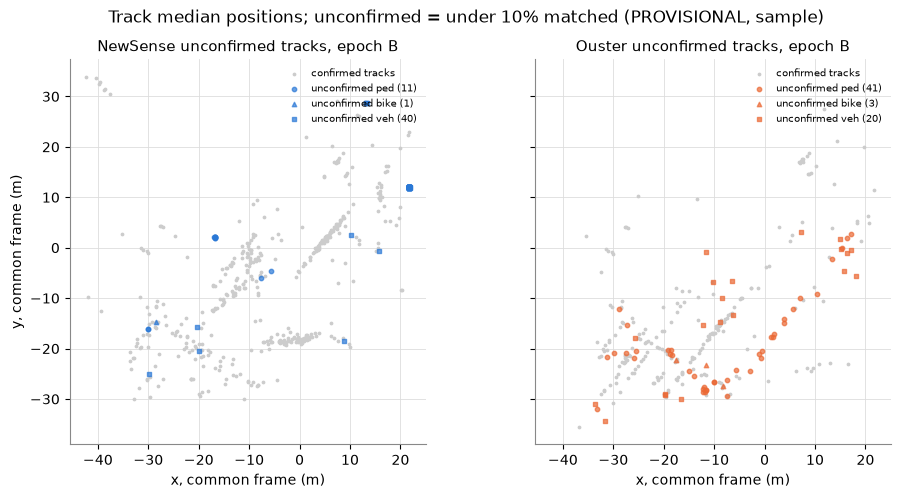

In [15]:
UN = pd.concat([sc.unconfirmed_tracks(NSF, TRACKS[("newsense", "filtered")]),
                sc.unconfirmed_tracks(OUF, TRACKS[("ouster", "filtered")])])
UN_SUM = sc.unconfirmed_summary(UN)
sc.save_table(UN_SUM, cfg, "unconfirmed_tracks")
VIDEO = sc.video_candidates(UN)
sc.save_table(VIDEO, cfg, "video_check_candidates")
display(UN_SUM)
print("video-check candidates per sensor:", VIDEO.groupby("sensor").size().to_dict())
fig = sc.plot_unconfirmed_map(UN, "B", TAG); sc.save_fig(fig, cfg, "unconfirmed_map_epochB"); plt.show()

## 6. Night check for NewSense ghosts
Static VRU tracks that only NewSense sees could be real people waiting whom the Ouster misses. They could also
be false detections on poles and signs.
- **Night data.** At night almost nobody is on the street, so static long VRU tracks there mark fixed-structure
  ghosts. They are mapped on the same 2 m grid.
- **Day comparison.** The table gives the share of daytime unconfirmed static VRU detections that fall into those
  night cells. Confirmed static VRU detections are shown as a baseline.
- **Reading the table.** An unconfirmed share well above the baseline points to ghosts.

,night_static_vru_tracks,night_cells,epoch,detections,n_det,share_in_night_static_cells
0,5,3,A,unconfirmed (unmatched),250,0.000
1,5,3,A,confirmed (matched),2300,0.003
2,5,3,B,unconfirmed (unmatched),473,0.000
3,5,3,B,confirmed (matched),1389,0.003


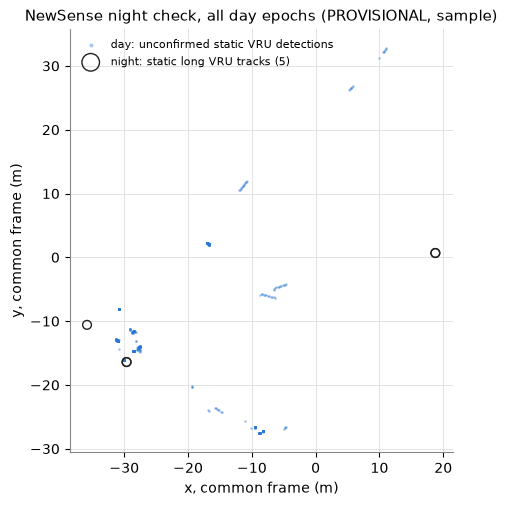

In [16]:
NIGHT = sc.make_variant(sc.load_sensor("newsense", FILES["newsense_night"], cfg["night"], day="29N"), "filtered")
NIGHT_KEYS, NIGHT_ST = sc.night_static_cells(NIGHT)
NIGHT_TAB = sc.night_overlap(NSF, TRACKS[("newsense", "filtered")], NIGHT_KEYS)
NIGHT_TAB.insert(0, "night_static_vru_tracks", len(NIGHT_ST)); NIGHT_TAB.insert(1, "night_cells", len(NIGHT_KEYS))
sc.save_table(NIGHT_TAB, cfg, "night_check")
display(NIGHT_TAB)
fig = sc.plot_night(NIGHT_ST, NSF, TRACKS[("newsense", "filtered")], TAG); sc.save_fig(fig, cfg, "night_check_map"); plt.show()

## 7. VRU counts per 5 minutes
A valid traversal is a `ped` or `bike` track that lasts at least 2 s and moves at least 3 m. It is counted in the
window where it starts.
- **Reading the figures.** The counts should track each other over time, and the per-window points should sit
  near the diagonal.
- **Caution.** A sensor that fragments tracks counts *higher*, so a higher count is not better by itself.

sensor       newsense  ouster
epoch group                  
B     bike         12       8
      ped          32      56
A     bike         10      20
      ped          24      24

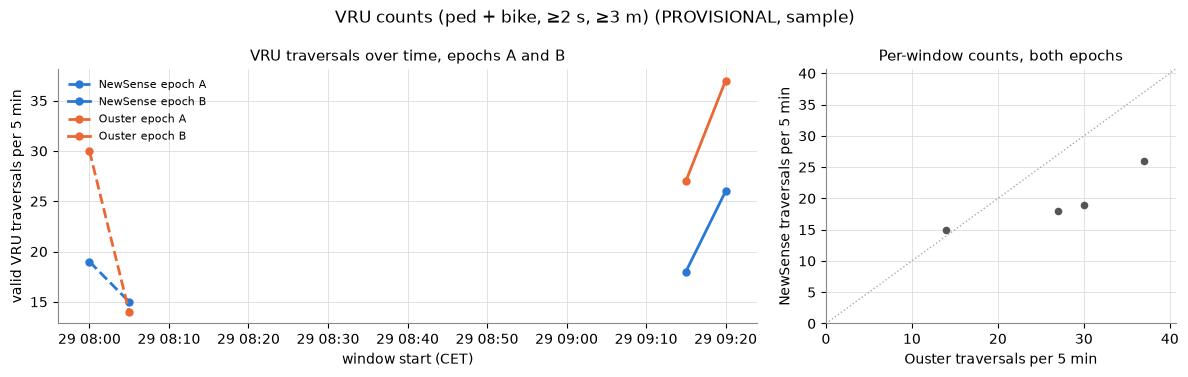

In [17]:
COUNTS = pd.concat([sc.vru_counts(TRACKS[(s, "filtered")], s) for s in sc.SENSORS], ignore_index=True)
sc.save_table(COUNTS, cfg, "vru_counts_per_5min")
display(COUNTS.pivot_table(index=["epoch", "group"], columns="sensor", values="n", aggfunc="sum")
        .sort_index(ascending=[False, True]))
fig = sc.plot_counts(COUNTS, TAG); sc.save_fig(fig, cfg, "vru_counts"); plt.show()

## 8. NewSense on 28.10 versus 29.10
The Ouster has no data on 28.10, so a same-time comparison is not possible on that day. The single-sensor
metrics are computed for NewSense on 28.10 and shown next to the 29.10 NewSense values for the same clock hours.
- **Reading the figure.** Similar bars mean the NewSense behaviour seen on 29.10 is typical. Large differences
  mean one day is unusual.

epoch                          B                                                      
group                       bike                  ped                   veh           
day                           28        29         28         29         28         29
n_tracks                  29.000    18.000     85.000  6.500e+01    268.000    404.000
n_det                   3123.000  2063.000  12158.000  5.335e+03  29936.000  35334.000
flicker_track_share        0.069     0.056      0.035  4.615e-02      0.030      0.045
flicker_det_share          0.006     0.005      0.002  5.623e-03      0.003      0.005
gap_track_share            0.000     0.000      0.000  0.000e+00      0.000      0.000
gap_mean_missing_share     0.000     0.000      0.000  0.000e+00      0.000      0.000
class_multi_share          0.000     0.000      0.000  0.000e+00      0.000      0.000
unk_det_share              0.000     0.000      0.000  0.000e+00      0.000      0.000
implausible_step_share     0.000     0.000      0.002  7.590e-04      0.000      0.000
step_speed_p99             5.662     5.873      2.917  3.100e+00     12.798     12.296
n_steps                 3094.000  2045.000  12073.000  5.270e+03  29668.000  34930.000
jitter_rms_m               0.102     0.087      0.065  6.858e-02      0.171      0.160
n_jitter                2834.000  1809.000  10359.000  3.637e+03  28594.000  31154.000
static_long_count          0.000     1.000      4.000  1.000e+00      1.000      6.000
static_long_det_share      0.000     0.050      0.050  5.211e-02      0.005      0.038
handovers_per_100          0.000     0.000     23.457  1.406e+01      3.053      1.750
n_handover_tracks         29.000    17.000     81.000  6.400e+01    262.000    400.000

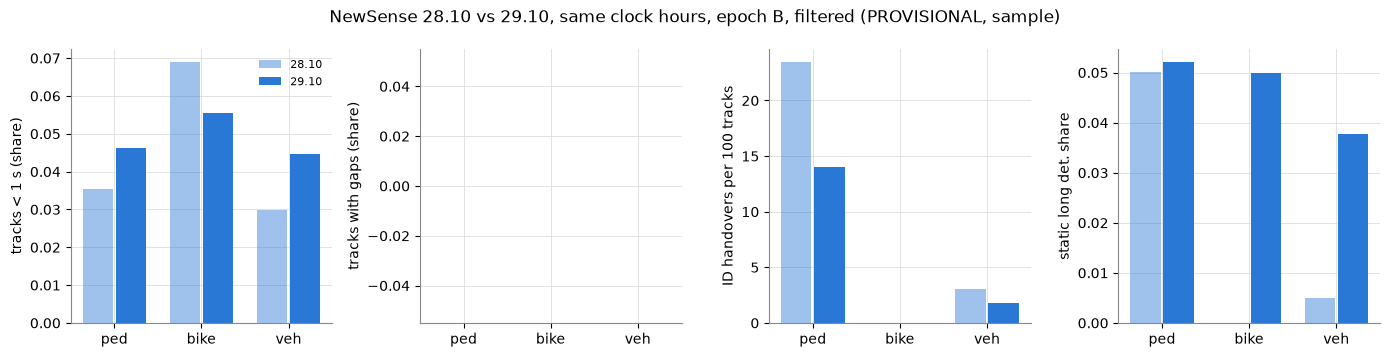

In [18]:
d28_ranges = cfg["day28"]
RAW28 = sc.load_sensor("newsense", FILES["newsense_28"], d28_ranges, day="28")
rows28 = []
for v in ["filtered", "raw"]:
    sd = sc.add_region(sc.make_variant(RAW28, v), REGION)
    rows28.append(sc.single_sensor_metrics(sd, v)[0])
S28 = pd.concat(rows28, ignore_index=True)
S29 = SINGLE[(SINGLE.sensor == "newsense") & SINGLE.epoch.isin(list(d28_ranges))]
DAY_CMP = pd.concat([S28, S29], ignore_index=True)
H28 = sc.stream_health(RAW28)
sc.save_table(DAY_CMP, cfg, "newsense_28_vs_29"); sc.save_table(H28, cfg, "stream_health_newsense_28")
display(DAY_CMP[DAY_CMP.variant == "filtered"].set_index(["epoch", "group", "day"]).drop(columns=["sensor", "variant"])
        .sort_index().T)
fig = sc.plot_day28(DAY_CMP[DAY_CMP.variant == "filtered"], TAG); sc.save_fig(fig, cfg, "newsense_28_vs_29"); plt.show()

## 9. Scorecard and conclusion
The scorecard has one row per metric, group, epoch and variant.
- **Columns.** Each row gives the NewSense value, the Ouster value, the direction that is better, the number of
  tracks behind each value, and the better sensor.
- **Unscored rows.** Context rows (counts, static tracks) and rows with too few tracks are not scored.
- **Ties.** Values within 5% of each other are ties.
- **Fragmentation rows.** These are already attributed to the sensor whose fragmentation they measure.

In [19]:
SCORE = sc.build_scorecard(SINGLE, FRAG, CONF, COUNTS)
sc.save_table(SCORE, cfg, "scorecard")
display(SCORE[(SCORE.variant == "filtered") & (SCORE.epoch == "B") & SCORE.group.isin(sc.VRU)]
        [["metric", "group", "newsense", "ouster", "n_newsense", "n_ouster", "direction", "better"]])

,metric,group,newsense,ouster,n_newsense,n_ouster,direction,better
0,class_multi_share,ped,0.000e+00,0.000e+00,65,95,lower,tie
1,confirmation_rate_moving,ped,9.577e-01,5.224e-01,34,85,higher,newsense
2,confirmation_rate_static,ped,7.543e-01,3.655e-01,35,43,higher,n/a (context)
3,flicker_det_share,ped,5.623e-03,1.295e-02,65,95,lower,newsense
4,flicker_track_share,ped,4.615e-02,2.947e-01,65,95,lower,newsense
5,frag_id_changes_per_min,ped,6.595e+00,4.189e+00,31,34,lower,ouster
6,frag_mean_n_ids,ped,1.968e+00,1.441e+00,31,34,lower,ouster
7,frag_share_n_ids_ge2,ped,4.839e-01,3.235e-01,31,34,lower,ouster
8,gap_mean_missing_share,ped,0.000e+00,1.546e-02,65,95,lower,newsense
9,gap_track_share,ped,0.000e+00,1.053e-01,65,95,lower,newsense


The next cell builds the conclusion from the scorecard of this run.
- **Decision rows.** The `ped` and `bike` rows of the filtered variant in epoch B, scored metrics only.
- **Rule.** A sensor is recommended only if it is better on at least two thirds of the comparable rows and does
  not lose the fragmentation rows. Both conditions must hold with and without the gap and class-stability rows.
  Otherwise the evidence is reported as mixed, with the split.
- **Vehicle rows** are shown as context only, because the project is about VRUs.

In [20]:
SUMMARY = sc.decide(SCORE, RUN_MODE)
print(SUMMARY)
with open(cfg["out"] / "tables" / "conclusion.txt", "w") as f:
    f.write(SUMMARY + "\n")
print(f"\ntotal notebook time {time.time() - T_START:.0f} s (cache build {T_CACHE:.0f} s), peak RSS {sc.rss_mb():.0f} MB, "
      f"cache {sc.cache_size_mb():.0f} MB")

PROVISIONAL: sample mode, based on 10 minutes per epoch. Not a basis for a decision.
Run mode: sample. Decision rows: filtered variant, epoch B, ped and bike, scored metrics.
Comparable rows: 21 (rows skipped as n/a: 3).
NewSense better on 16 rows: confirmation_rate_moving[ped], flicker_det_share[ped], flicker_track_share[ped], gap_mean_missing_share[ped], gap_track_share[ped], handovers_per_100[ped], implausible_step_share[ped], jitter_rms_m[ped], class_multi_share[bike], confirmation_rate_moving[bike], flicker_track_share[bike], gap_mean_missing_share[bike], gap_track_share[bike], handovers_per_100[bike], implausible_step_share[bike], jitter_rms_m[bike]
Ouster better on 4 rows: frag_id_changes_per_min[ped], frag_mean_n_ids[ped], frag_share_n_ids_ge2[ped], flicker_det_share[bike]
Ties: 1
Tally with all rows: NewSense 16, Ouster 4, ties 1 of 21; fragmentation rows NewSense 0, Ouster 3.
Tally without gap_track_share, gap_mean_missing_share, class_multi_share (rows NewSense cannot lose b

### Limits (they hold in both run modes)
- **Short window.** The full comparison covers about four hours of one morning (29.10, 07:20–11:25 CET). Sample
  mode covers only 10 minutes per epoch.
- **No ground truth.** There is no independent ground truth. Unmatched detections are ambiguous: they are either
  false detections by one sensor or misses by the other. The video-check list is the way to resolve them.
- **Ouster reconfiguration.** The Ouster was being reconfigured that morning:
  - it was recalibrated at 08:13 CET, so epoch A uses a different transform;
  - it dropped frames frequently before about 08:05 CET.
- **Untested conditions.** Night, rain and the afternoon peak are untested for the Ouster.
- **Transform accuracy.** The rigid transforms were fitted on moving vehicles. A residual misalignment of a few
  decimetres affects the 2 m matching gate very little, but it slightly favours large objects.